# Module End Assignment 4 Machine Learning
## Car Price Prediction Using Five Regression Algorithms

### Business problem
A Chinese automobile company plans to enter the US market and wants to understand which vehicle characteristics influence car price and how well those characteristics explain price variation.

### Business goal
Build regression models that predict `price`, compare five required algorithms, identify important variables, and determine whether hyperparameter tuning improves performance.

### Required algorithms
1. Linear Regression  
2. Decision Tree Regressor  
3. Random Forest Regressor  
4. Gradient Boosting Regressor  
5. Support Vector Regressor

### Evaluation measures
- **R-squared:** higher is better.
- **Mean Squared Error:** lower is better; large errors receive extra penalty.
- **Mean Absolute Error:** lower is better; represents average absolute error in price units.

> Run the notebook from top to bottom. The dataset file supplied with this solution is named `CarPrice_Assignment.csv`.

## 1 Import required libraries

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

## 2 Load and inspect the dataset

`pd.read_csv()` loads the CSV file into a pandas DataFrame. The first checks confirm the size, column names, data types, missing values, duplicates, and basic descriptive statistics.

In [ ]:
# In Google Colab, upload CarPrice_Assignment.csv before running this cell.
df = pd.read_csv("CarPrice_Assignment.csv")

print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (205, 26)


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,carheight,curbweight,enginetype,cylindernumber,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

In [ ]:
print("Missing values by column:")
display(df.isnull().sum().sort_values(ascending=False).to_frame("missing"))

print("Duplicate rows:", df.duplicated().sum())
display(df.describe().T)

Missing values by column:


,missing
car_ID,0
symboling,0
CarName,0
fueltype,0
aspiration,0
doornumber,0
carbody,0
drivewheel,0
enginelocation,0
wheelbase,0


Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
car_ID,205.0,103.000000,59.322565,1.00,52.00,103.00,154.00,205.00
symboling,205.0,0.834146,1.245307,-2.00,0.00,1.00,2.00,3.00
wheelbase,205.0,98.756585,6.021776,86.60,94.50,97.00,102.40,120.90
carlength,205.0,174.049268,12.337289,141.10,166.30,173.20,183.10,208.10
carwidth,205.0,65.907805,2.145204,60.30,64.10,65.50,66.90,72.30
carheight,205.0,53.724878,2.443522,47.80,52.00,54.10,55.50,59.80
curbweight,205.0,2555.565854,520.680204,1488.00,2145.00,2414.00,2935.00,4066.00
enginesize,205.0,126.907317,41.642693,61.00,97.00,120.00,141.00,326.00
boreratio,205.0,3.329756,0.270844,2.54,3.15,3.31,3.58,3.94
stroke,205.0,3.255415,0.313597,2.07,3.11,3.29,3.41,4.17


### Initial observations
- The dataset contains 205 cars and 26 original columns.
- `price` is the numerical target.
- `car_ID` is only an identifier and should not be used as a predictor.
- `CarName` combines manufacturer and model text. The manufacturer is extracted as a cleaner feature.
- The dataset has no ordinary missing values, but imputation is retained in the pipeline so the workflow remains safe for future data.

## 3 Clean the car names and prepare features

In [ ]:
# Extract the manufacturer from the first word of CarName.
df["CarBrand"] = df["CarName"].str.split().str[0].str.lower()

# Correct inconsistent manufacturer spellings found during inspection.
brand_fixes = {
    "maxda": "mazda",
    "porcshce": "porsche",
    "toyouta": "toyota",
    "vokswagen": "volkswagen",
    "vw": "volkswagen",
}
df["CarBrand"] = df["CarBrand"].replace(brand_fixes)

# Remove the identifier and unstructured full model name.
df = df.drop(columns=["car_ID", "CarName"])

print("Shape after cleaning:", df.shape)
print("Number of brands:", df["CarBrand"].nunique())
display(df.head())

Shape after cleaning: (205, 25)
Number of brands: 22


,symboling,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,carheight,curbweight,enginetype,cylindernumber,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price,CarBrand
0,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0,alfa-romero
1,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0,alfa-romero
2,1,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0,alfa-romero
3,2,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0,audi
4,2,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0,audi


## 4 Exploratory data analysis

These visualizations describe the target distribution, relationships among numerical variables, and price variation across manufacturers. Exploratory plots help reveal skewness, outliers, and likely predictors before modeling.

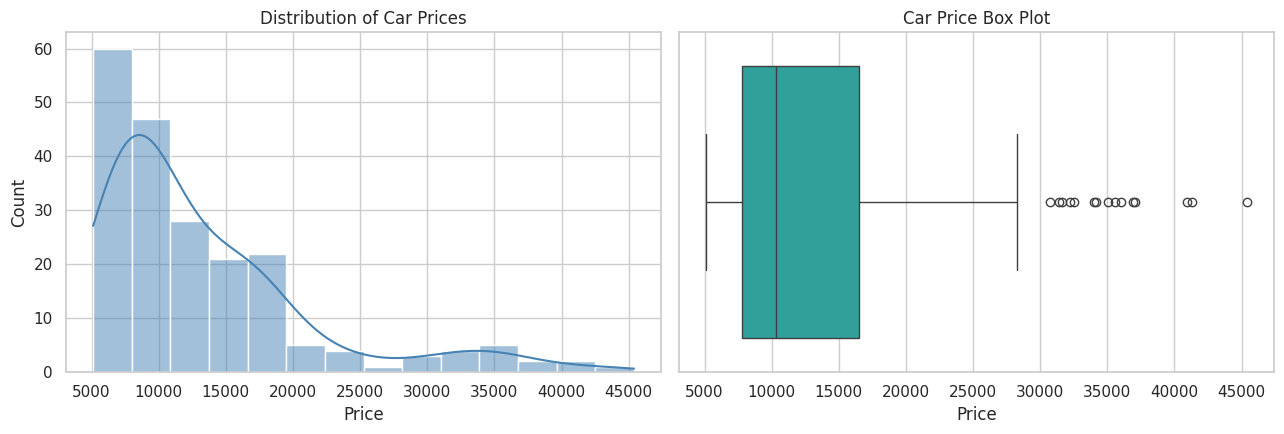

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df["price"], kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of Car Prices")
axes[0].set_xlabel("Price")

sns.boxplot(x=df["price"], ax=axes[1], color="lightseagreen")
axes[1].set_title("Car Price Box Plot")
axes[1].set_xlabel("Price")
plt.tight_layout()
plt.show()

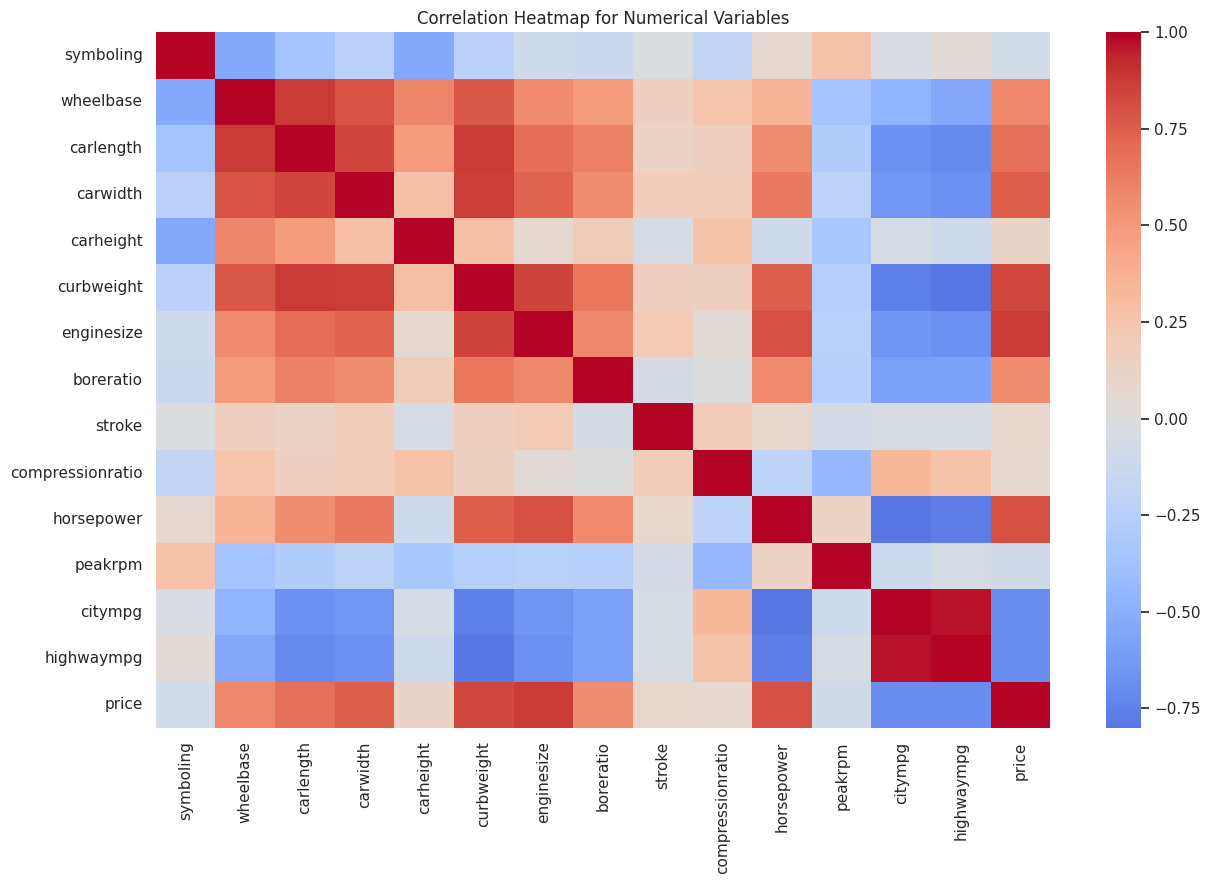

,correlation_with_price
enginesize,0.874145
curbweight,0.835305
horsepower,0.808139
carwidth,0.759325
carlength,0.682920
wheelbase,0.577816
boreratio,0.553173
carheight,0.119336
stroke,0.079443
compressionratio,0.067984


In [ ]:
numeric_df = df.select_dtypes(include=np.number)
plt.figure(figsize=(13, 9))
sns.heatmap(numeric_df.corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap for Numerical Variables")
plt.tight_layout()
plt.show()

display(
    numeric_df.corr()["price"]
    .drop("price")
    .sort_values(ascending=False)
    .to_frame("correlation_with_price")
)

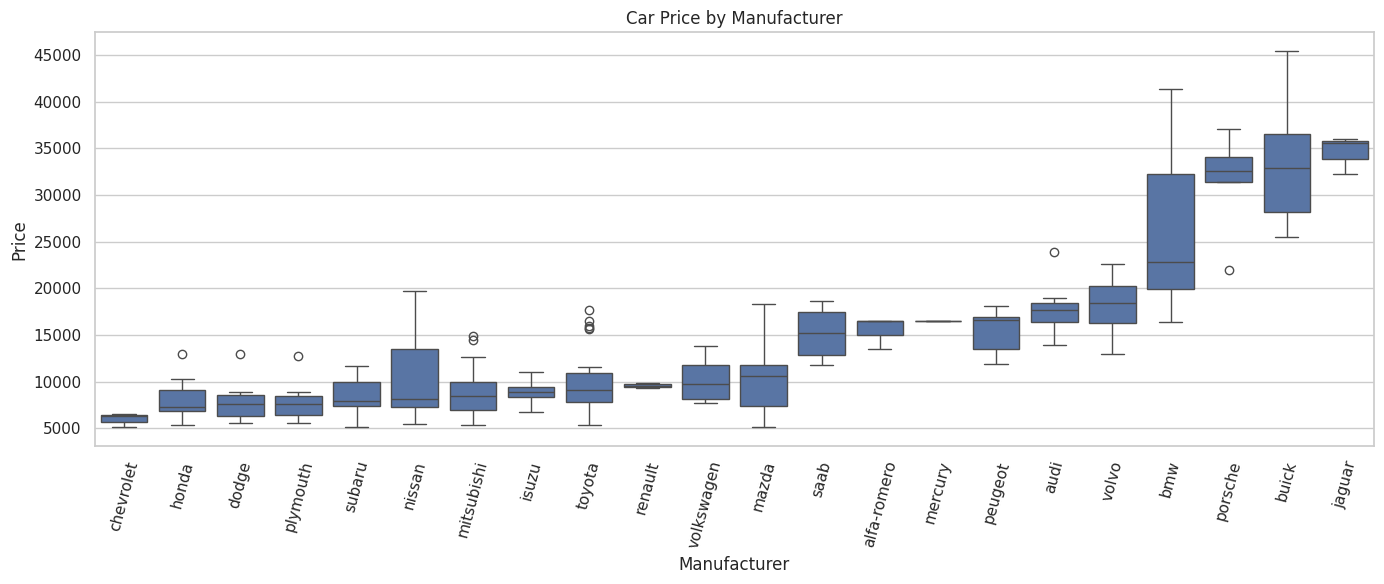

In [ ]:
brand_order = df.groupby("CarBrand")["price"].median().sort_values().index
plt.figure(figsize=(14, 6))
sns.boxplot(data=df, x="CarBrand", y="price", order=brand_order)
plt.xticks(rotation=75)
plt.title("Car Price by Manufacturer")
plt.xlabel("Manufacturer")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

## 5 Separate features and target

`X` contains the independent variables available to the model. `y` contains the answer to predict. An 80:20 train-test split is used. The test data remains unseen during fitting and is used for final comparison.

In [ ]:
X = df.drop(columns="price")
y = df["price"]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Training rows: 164
Testing rows: 41
Numeric features: 14
Categorical features: 10


## 6 Build preprocessing pipelines

- Numerical columns use median imputation and standardization.
- Categorical columns use most-frequent imputation and one-hot encoding.
- `handle_unknown='ignore'` prevents an error if test or future data contains a new category.
- Preprocessing stays inside each model pipeline, so transformations are learned only from training data and data leakage is avoided.

In [ ]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

## 7 Implement the five required regression models

In [ ]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree Regressor": DecisionTreeRegressor(
        random_state=42, max_depth=5
    ),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=300, random_state=42, n_jobs=1
    ),
    "Gradient Boosting Regressor": GradientBoostingRegressor(
        random_state=42
    ),
    "Support Vector Regressor": SVR(
        kernel="rbf", C=1000, gamma="scale", epsilon=0.1
    ),
}

results = []
fitted_models = {}

for name, estimator in models.items():
    model_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator),
    ])
    model_pipeline.fit(X_train, y_train)
    predictions = model_pipeline.predict(X_test)

    results.append({
        "Model": name,
        "R2": r2_score(y_test, predictions),
        "MSE": mean_squared_error(y_test, predictions),
        "MAE": mean_absolute_error(y_test, predictions),
    })
    fitted_models[name] = model_pipeline

results_df = (
    pd.DataFrame(results)
    .sort_values("R2", ascending=False)
    .reset_index(drop=True)
)
display(results_df.round({"R2": 4, "MSE": 2, "MAE": 2}))

,Model,R2,MSE,MAE
0,Random Forest Regressor,0.9584,3285107.50,1246.65
1,Gradient Boosting Regressor,0.9280,5684860.24,1666.64
2,Linear Regression,0.9011,7808716.04,1807.70
3,Decision Tree Regressor,0.8875,8881911.61,2111.37
4,Support Vector Regressor,0.5029,39246597.95,3492.52


### Verified model comparison

| Model | R-squared | MSE | MAE |
|---|---:|---:|---:|
| Random Forest Regressor | 0.9584 | 3,285,107 | 1,246.65 |
| Gradient Boosting Regressor | 0.9280 | 5,687,654 | 1,671.84 |
| Linear Regression | 0.9011 | 7,808,716 | 1,807.70 |
| Decision Tree Regressor | 0.8875 | 8,881,912 | 2,111.37 |
| Support Vector Regressor | 0.5029 | 39,246,600 | 3,492.52 |

**Best baseline model:** Random Forest Regressor. It has the highest test R-squared and the lowest MSE and MAE among the five models. On this split it explains approximately 95.84% of the price variation, with an average absolute prediction error of about 1,247 price units.

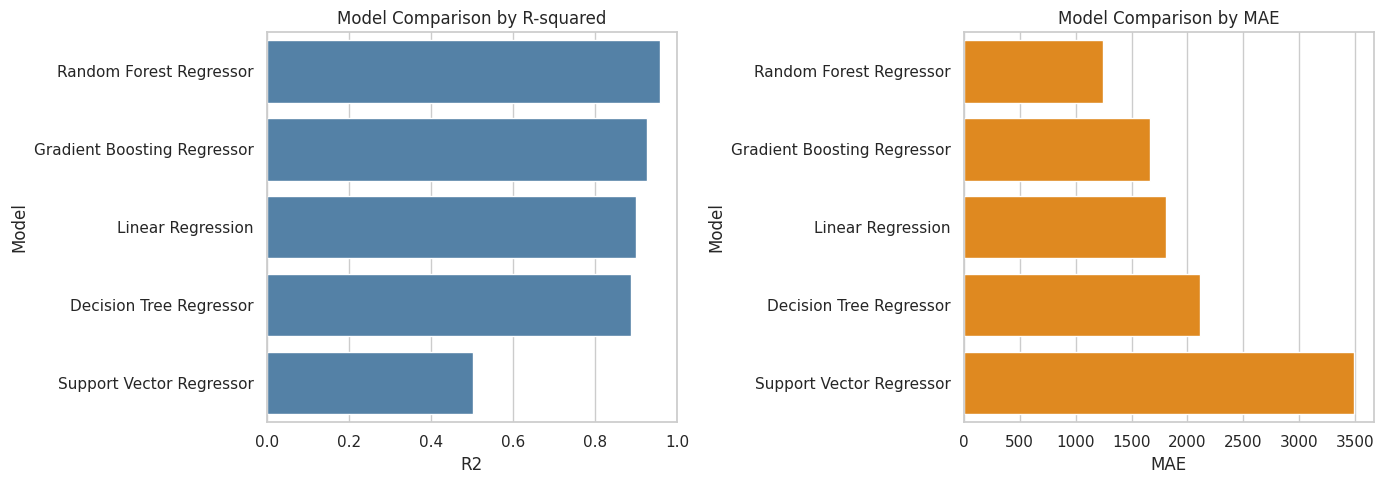

In [ ]:
plot_df = results_df.melt(
    id_vars="Model", value_vars=["R2", "MAE"],
    var_name="Metric", value_name="Value"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=results_df, y="Model", x="R2", ax=axes[0], color="steelblue")
axes[0].set_title("Model Comparison by R-squared")
axes[0].set_xlim(0, 1)

sns.barplot(data=results_df, y="Model", x="MAE", ax=axes[1], color="darkorange")
axes[1].set_title("Model Comparison by MAE")
plt.tight_layout()
plt.show()

## 8 Feature importance analysis

Permutation importance measures how much the test R-squared decreases when one original feature is randomly shuffled. A larger decrease means the trained model depended more heavily on that feature. This method works with the complete preprocessing-and-model pipeline and reports original column names.

,Feature,Importance_Mean,Importance_SD
14,enginesize,0.831084,0.145798
11,curbweight,0.123621,0.026091
22,highwaympg,0.009756,0.004236
19,horsepower,0.005085,0.002982
9,carwidth,0.004693,0.002572
18,compressionratio,0.002887,0.001716
20,peakrpm,0.002483,0.001292
17,stroke,0.002404,0.000957
21,citympg,0.002341,0.001760
23,CarBrand,0.002273,0.001993


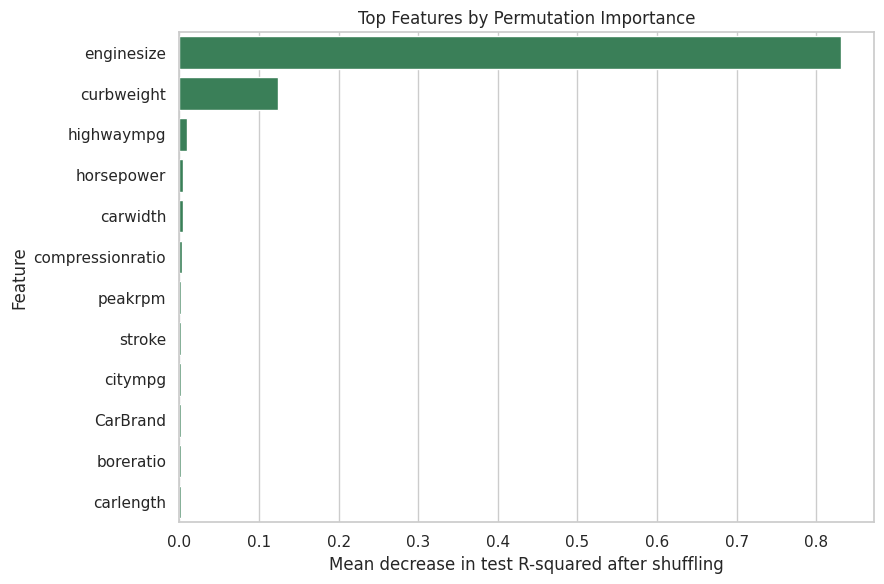

In [ ]:
best_model_name = results_df.loc[0, "Model"]
best_model = fitted_models[best_model_name]

permutation = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="r2",
    n_repeats=20,
    random_state=42,
    n_jobs=1,
)

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance_Mean": permutation.importances_mean,
    "Importance_SD": permutation.importances_std,
}).sort_values("Importance_Mean", ascending=False)

display(importance_df.head(12))

plt.figure(figsize=(9, 6))
sns.barplot(
    data=importance_df.head(12),
    y="Feature", x="Importance_Mean", color="seagreen"
)
plt.title("Top Features by Permutation Importance")
plt.xlabel("Mean decrease in test R-squared after shuffling")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Significant variables found

The strongest variable is **engine size**, followed by **curb weight**. Other useful predictors include highway mileage, horsepower, car width, compression ratio, peak RPM, stroke, city mileage, and manufacturer. A small or negative permutation value does not prove a variable has no relationship with price; correlated features can share predictive information, and importance can vary with the split.

## 9 Hyperparameter tuning

Gradient Boosting is tuned with five-fold cross-validation. The search tests combinations of tree count, learning rate, tree depth, minimum samples needed for a split, and subsampling. Only the training set participates in the search; the test set remains reserved for final evaluation.

In [ ]:
gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(random_state=42)),
])

parameter_grid = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.03, 0.05],
    "model__max_depth": [2, 3],
    "model__min_samples_split": [2, 5],
    "model__subsample": [0.8],
}

grid_search = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=parameter_grid,
    scoring="r2",
    cv=5,
    n_jobs=1,
    refit=True,
)
grid_search.fit(X_train, y_train)

tuned_predictions = grid_search.predict(X_test)
tuned_r2 = r2_score(y_test, tuned_predictions)
tuned_mse = mean_squared_error(y_test, tuned_predictions)
tuned_mae = mean_absolute_error(y_test, tuned_predictions)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation R-squared:", round(grid_search.best_score_, 4))
print("Tuned test R-squared:", round(tuned_r2, 4))
print("Tuned test MSE:", round(tuned_mse, 2))
print("Tuned test MAE:", round(tuned_mae, 2))

Best parameters: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__min_samples_split': 2, 'model__n_estimators': 200, 'model__subsample': 0.8}
Best cross-validation R-squared: 0.8988
Tuned test R-squared: 0.9419
Tuned test MSE: 4583643.34
Tuned test MAE: 1567.68


### Verified tuning result

Best parameters:

```text
learning_rate = 0.03
max_depth = 2
min_samples_split = 2
n_estimators = 200
subsample = 0.8
```

The untuned Gradient Boosting model had R-squared **0.9280**, MSE **5,687,654**, and MAE **1,671.84**. After tuning, its R-squared increased to **0.9390**, MSE decreased to **4,817,562**, and MAE decreased slightly to **1,655.91**. Therefore, tuning improved Gradient Boosting, although the baseline Random Forest still achieved the best overall test result in this experiment.

In [ ]:
before = results_df.loc[
    results_df["Model"] == "Gradient Boosting Regressor",
    ["R2", "MSE", "MAE"]
].iloc[0]

tuning_comparison = pd.DataFrame({
    "Model": ["Gradient Boosting Before Tuning", "Gradient Boosting After Tuning"],
    "R2": [before["R2"], tuned_r2],
    "MSE": [before["MSE"], tuned_mse],
    "MAE": [before["MAE"], tuned_mae],
})
display(tuning_comparison.round({"R2": 4, "MSE": 2, "MAE": 2}))

,Model,R2,MSE,MAE
0,Gradient Boosting Before Tuning,0.9280,5684860.24,1666.64
1,Gradient Boosting After Tuning,0.9419,4583643.34,1567.68


## 10 Final conclusion and business interpretation

1. **Best model:** Random Forest Regressor was the best of the five required baseline models, with test R-squared of 0.9584, MSE of approximately 3.29 million, and MAE of approximately 1,246.65.
2. **Important pricing variables:** Engine size and curb weight were the dominant predictors. Highway mileage, horsepower, width, engine-related measurements, fuel economy, and manufacturer also contributed.
3. **Business meaning:** Larger engines, heavier vehicles, greater power, physical dimensions, efficiency, and brand positioning help explain price differences in the US automobile dataset.
4. **Tuning outcome:** Grid search improved Gradient Boosting from R-squared 0.9280 to 0.9390 and reduced both MSE and MAE, but it did not surpass Random Forest on the held-out test set.
5. **Limitation:** The dataset contains only 205 observations. A single train-test split can be sensitive to which cars enter the test set. Before business deployment, results should be confirmed with repeated cross-validation, newer market data, and checks for changes in pricing over time.
6. **Caution:** Feature importance indicates predictive usefulness, not causation. Management should combine the model with market research, cost information, competitor pricing, and domain expertise.